In [1]:
# import packages and data
import pandas as pd
import numpy as np
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from joblib import dump, load
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)
from sklearn.model_selection import cross_validate, GridSearchCV
import os
import matplotlib.pyplot as plt

exp_data = pd.read_csv(
    "/data/jxwang_data/OvarianProS/output/step3_ML_data/ML_data_ov_s1_ctrl.csv",
    index_col=0,
)
exp_data = exp_data.loc[(exp_data["label"] == "ctrl") | (exp_data["label"] == "ov_s1"),]
min_features_to_select = int((exp_data.shape[1] - 1) / 10)


In [2]:
def labeling(row):
    label = row["label"]
    if label == "ctrl":
        return 0
    else:
        return 1


In [3]:
exp_data["label"] = exp_data.apply(labeling, axis=1)
X = exp_data.iloc[:, :-1]
y = exp_data.iloc[:, -1]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
clf = LogisticRegression(max_iter=5000)
cv = StratifiedKFold(3)


In [4]:
if os.path.exists(
    "/data/jxwang_data/OvarianProS/output/step4_feature_selection/ov_s1_ctrl.fs"
):
    X, y, feas = load(
        "/data/jxwang_data/OvarianProS/output/step4_feature_selection/ov_s1_ctrl.fs"
    )
else:
    rfecv = RFECV(
        estimator=clf,
        step=1,
        cv=cv,
        scoring="f1",
        min_features_to_select=min_features_to_select,
        n_jobs=-1,
    )
    rfecv.fit(X, y)
    cv_results = pd.DataFrame(rfecv.cv_results_)
    print(f"Optimal number of features: {rfecv.n_features_}")
    print(max(cv_results["mean_test_score"]))
    df_selected = exp_data.iloc[:, :-1].loc[:, rfecv.get_support()]
    X_selected = scaler.fit_transform(df_selected)
    fs_res = [X_selected, y, df_selected.columns]
    dump(
        fs_res,
        "/data/jxwang_data/OvarianProS/output/step4_feature_selection/ov_s1_ctrl.fs",
    )
    X, y, feas = load(
        "/data/jxwang_data/OvarianProS/output/step4_feature_selection/ov_s1_ctrl.fs"
    )


Optimal number of features: 17
0.8529239766081872


In [5]:
param_grid = {
    "C": [1e-4, 1e-3, 1e-2, 1e-1, 1, 1e1, 1e2, 1e3, 1e4],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear", "saga"],
    "class_weight": [None, "balanced"],
}


In [6]:
grid_search = GridSearchCV(clf, param_grid, cv=cv, scoring='f1')
grid_search.fit(X, y)
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)
clf = grid_search.best_estimator_

Best parameters: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'saga'}
Best score: 0.9218708827404479


In [7]:
fbeta_scorer = make_scorer(fbeta_score, beta=2)
cv_res = cross_validate(
    clf,
    X,
    y,
    cv=cv,
    scoring={
        "fbeta": fbeta_scorer,
        "auc": "roc_auc",
        "accuracy": "balanced_accuracy",
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "AP": "average_precision",
    },
    return_train_score=True,
)

result_df = pd.DataFrame(
    {
        "accuracy": [np.mean(cv_res["test_accuracy"])],
        "f1": [np.mean(cv_res["test_f1"])],
        "precision": [np.mean(cv_res["test_precision"])],
        "recall": [np.mean(cv_res["test_recall"])],
        "auc": [np.mean(cv_res["test_auc"])],
        "fbeta": [np.mean(cv_res["test_fbeta"])],
        "AP": [np.mean(cv_res["test_AP"])],
    }
)
print(result_df)


   accuracy        f1  precision    recall       auc     fbeta        AP
0   0.93341  0.921871   0.969697  0.881313  0.975516  0.896784  0.968261


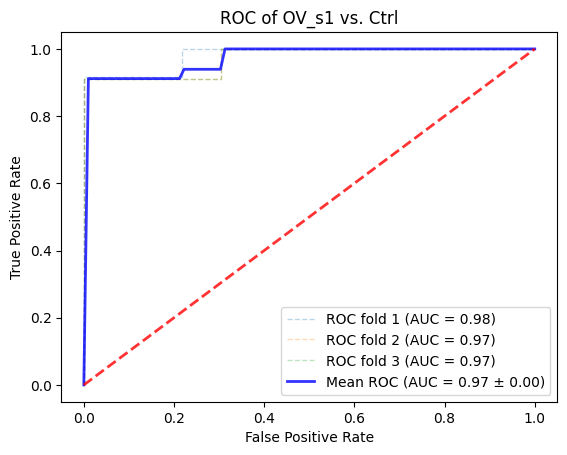

In [8]:
tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)
for train, test in cv.split(X, y):
    clf.fit(X[train], y[train])
    y_scores = clf.decision_function(X[test])
    fpr, tpr, _ = roc_curve(y[test], y_scores)
    tprs.append(np.interp(mean_fpr, fpr, tpr))
    tprs[-1][0] = 0.0
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    plt.plot(
        fpr,
        tpr,
        lw=1,
        alpha=0.3,
        linestyle="--",
        label=f"ROC fold {len(tprs)} (AUC = {roc_auc:.2f})",
    )

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

plt.plot(
    mean_fpr,
    mean_tpr,
    color="b",
    label=f"Mean ROC (AUC = {mean_auc:.2f} ± {std_auc:.2f})",
    lw=2,
    alpha=0.8,
)

plt.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", alpha=0.8)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC of OV_s1 vs. Ctrl")
plt.legend(loc="lower right")
plt.savefig("/data/jxwang_data/OvarianProS/output/step5_model/ov_s1_ctrl_roc.png")


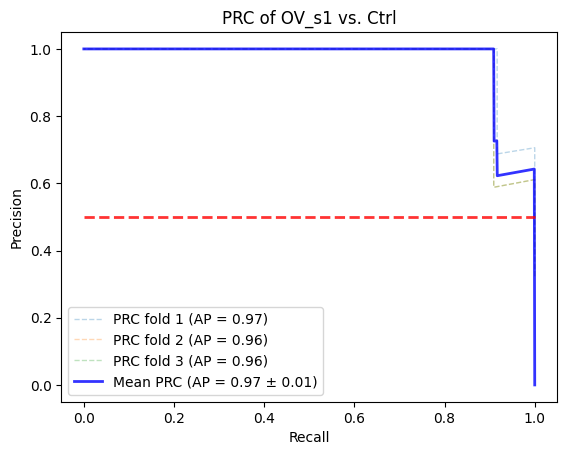

In [9]:
precisions = []
recalls = []
average_precisions = []
mean_recall = np.linspace(0, 1, 1000)

for i, (train, test) in enumerate(cv.split(X, y)):
    clf.fit(X[train], y[train])
    y_scores = clf.decision_function(X[test])
    precision, recall, _ = precision_recall_curve(y[test], y_scores)
    average_precision = auc(recall, precision)
    average_precisions.append(average_precision)
    interp_precision = np.interp(mean_recall, recall[::-1], precision[::-1])
    interp_precision[0] = 1.0
    interp_precision[-1] = 0.0
    precisions.append(interp_precision)
    plt.plot(
        recall,
        precision,
        lw=1,
        alpha=0.3,
        linestyle="--",
        label=f"PRC fold {i+1} (AP = {average_precision:.2f})",
    )


mean_precision = np.mean(precisions, axis=0)
mean_average_precision = np.mean(average_precisions)
std_average_precision = np.std(average_precisions)


plt.plot(
    mean_recall,
    mean_precision,
    color="b",
    label=f"Mean PRC (AP = {mean_average_precision:.2f} ± {std_average_precision:.2f})",
    lw=2,
    alpha=0.8,
)


plt.plot([0, 1], [0.5, 0.5], linestyle="--", lw=2, color="r", alpha=0.8)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PRC of OV_s1 vs. Ctrl")
plt.legend(loc="lower left")
plt.savefig("/data/jxwang_data/OvarianProS/output/step5_model/ov_s1_ctrl_prc.png")
